---
---

<h1><center><ins>Exercise Sheet 6</ins></center></h1>
<h2><center>Numerical Methods <br>

---
---

In [18]:
import matplotlib.pyplot as plt
import numpy as np
from numpy import log

## Exercise 1 - Radioactive decay

Radioactive decay is the process by which an unstable atomic nucleus loses energy by radiation. The fundamental law of radioactive decay is based on the fact that the decay, i.e. the transition of a parent nucleus to a daughter nucleus is a purely statistical process. The disintegration (decay) probability is a fundamental property of an atomic nucleus and remains equal in time. Mathematically this law is expressed as: 

$$ \frac{d N}{dt} = - \lambda N \ , $$

where $N$ is the number of radioactive nuclei, $dN/dt$ the variation of this number per unit of time, and $\lambda$ is thus the probability of decay per nucleus per unit of time. A more intuitive representation of exponential decay is the time required for the decaying quantity to fall to one half of its initial value. This time, $t_{1/2}$, is called "half-life", and can be written in terms of the decay constant as:

$$ t_{1/2} = \frac{\ln(2)}{\lambda} \ . $$

Let's consider here Carbon-14, for which the decay constant is $\lambda \sim 1.21 \times 10^{-4}$ yr$^{-1}$, and which has a half-life $t_{1/2} \sim 5728$ yr. Its presence in organic materials is the basis of the radiocarbon dating method to date archaeological, geological and hydrogeological samples.

**(A)** Implement _**your own version**_ of the **Euler and Runge Kutta (order 2) algorithms**, and solve the differential equation above by using these methods. Compare the results you obtain to the analytic solution, which can be calculated as:

$$ N = N_0 \exp(-\lambda t) \ ,$$

where $N_0$ is the initial amount of the nuclei $[$i.e., $N(t = 0) = N_0]$.

**(B)** Compute your solution for a sufficient number of steps so that you can determine the **half-life** of Carbon-14. Pay attention to the size of the time-step you are using, and discuss your results when using different time-steps. Which method recovers a value of the half-life that is closer to the real one?

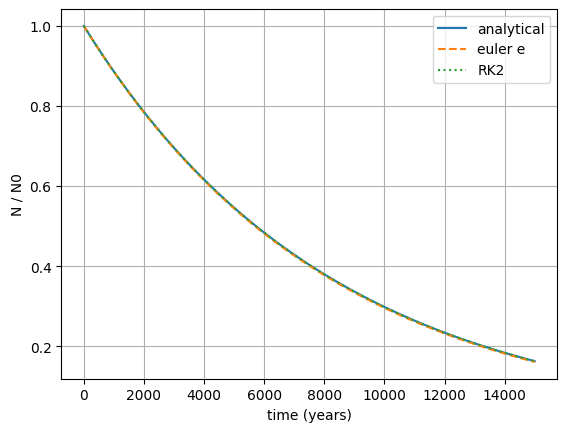

In [27]:
#a
import numpy as np
import matplotlib.pyplot as plt

lamb = 1.21e-4
N0 = 1
dt = 100
t = np.arange(0, 15000 + dt, dt)
def f(N):
    return -lamb * N
euler = np.zeros(len(t))
rk2 = np.zeros(len(t))
euler[0] = N0
rk2[0] = N0
for i in range(len(t)-1):
    euler[i+1] = euler[i] + dt * f(euler[i])
    k1 = f(rk2[i])
    k2 = f(rk2[i] + dt*k1/2)
    rk2[i+1] = rk2[i] + dt*k2
analytic = N0 * np.exp(-lamb*t)
plt.plot(t, analytic, label="analytical")
plt.plot(t, euler, "--", label="euler e")
plt.plot(t, rk2, ":", label="RK2")
plt.xlabel("time (years)")
plt.ylabel("N / N0")
plt.legend()
plt.grid()
plt.show()

In [29]:
#b
half_life = np.log(2) / lamb
print("analytical half-life:", half_life)
for dt in [1000, 500, 100, 10, 1]:
    t = np.arange(0, 15000 + dt, dt)
    euler = np.zeros(len(t))
    rk2 = np.zeros(len(t))
    euler[0] = N0
    rk2[0] = N0
    for i in range(len(t)-1):
        euler[i+1] = euler[i] + dt*f(euler[i])
        k1 = f(rk2[i])
        k2 = f(rk2[i] + dt*k1/2)
        rk2[i+1] = rk2[i] + dt*k2
    half_euler = t[np.argmin(abs(euler - N0/2))]
    half_rk2 = t[np.argmin(abs(rk2 - N0/2))]
    print(f"dt = {dt:4} | euler = {half_euler:.0f} yr | RK2 = {half_rk2:.0f} yr")

analytical half-life: 5728.489095536738
dt = 1000 | euler = 5000 yr | RK2 = 6000 yr
dt =  500 | euler = 5500 yr | RK2 = 5500 yr
dt =  100 | euler = 5700 yr | RK2 = 5700 yr
dt =   10 | euler = 5730 yr | RK2 = 5730 yr
dt =    1 | euler = 5728 yr | RK2 = 5728 yr


## Exercise 2 - The motion of a pendulum

The differential equation describing the motion of a simple pendulum of length $l$ is

$$ \frac{d^2 \theta}{dt} = - \frac{g}{l} \sin(\theta) \ , $$

where $g$ is the local acceleration of gravity (on Earth, $g = 9.8$ m/s$^2$). For this exercise, consider $l = 10$ m. Here we will consider the simple case in which the maximal displacement of the pendulum is small, so that we can use the approximation $\sin(\theta) \approx \theta$ and consider the following, simplified, equation:

$$ \frac{d^2 \theta}{dt} = - \frac{g}{l} \theta \ . $$

This equation can be solved analytically, giving the following expression for $\theta(t)$:

$$ \theta(t) = \theta_0 \cos \left(\sqrt{\frac{g}{l}} \, t \right) \ .$$

**(A)** Rewrite the above differential equation as a system of first-order differential equations, and solve it numerically by implementing _**your own version**_ of the **Euler method**. Consider that at a time $t = 0$ the pendulum is at $\theta = 0.1$ radians, and it is not moving. 

**(B)** What is the displacement ($\theta$) of the pendulum at a time $t = 20$ s, if you consider a time step $\tau = 0.2$ s in your ODE integrator? How different is the value you obtain from the true one (calculated with the above equation)? How small should the time step be, if you want to have a discrepancy of at most 0.01 in the value of $\theta(t = 20$ s$)$?

**(C)** Implement _**your own version**_ of the **Euler-Cromer and Runge Kutta (order 4) algorithms**, and solve the differential equation again by using these methods. How big is the discrepancy from the real solution for these methods, at a time $t = 20$ s, if you consider a time step $\tau = 0.2$ s?

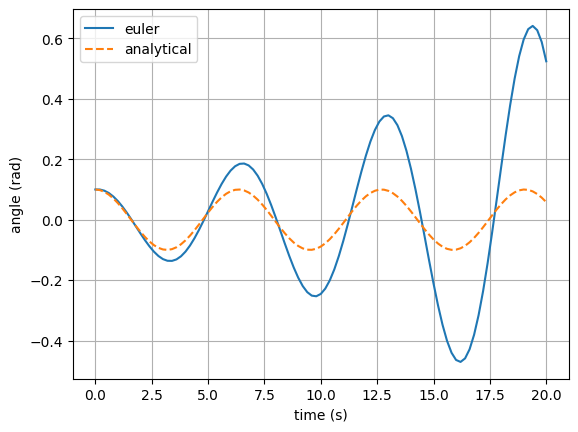

In [30]:
#a
g, l = 9.8, 10
dt = 0.2
t = np.arange(0, 20 + dt, dt)
theta = np.zeros(len(t))
omega = np.zeros(len(t))
theta[0] = 0.1
omega[0] = 0
for i in range(len(t)-1):
    theta[i+1] = theta[i] + dt * omega[i]
    omega[i+1] = omega[i] - dt * (g/l) * theta[i]
theta_exact = 0.1 * np.cos(np.sqrt(g/l) * t)
plt.plot(t, theta, label="euler")
plt.plot(t, theta_exact, "--", label="analytical")
plt.xlabel("time (s)")
plt.ylabel("angle (rad)")
plt.legend()
plt.grid()
plt.show()

In [32]:
#b
print("euler:", theta[-1])
print("analytical:", theta_exact[-1])
error = abs(theta[-1] - theta_exact[-1])
print("errror:", error)
for dt in [0.2, 0.1, 0.05, 0.01, 0.001]:
    t = np.arange(0, 20 + dt/2, dt)
    theta = np.zeros(len(t))
    omega = np.zeros(len(t))
    theta[0] = 0.1
    for i in range(len(t)-1):
        theta[i+1] = theta[i] + dt * omega[i]
        omega[i+1] = omega[i] - dt * (g/l) * theta[i]
    exact = 0.1 * np.cos(np.sqrt(g/l) * 20)
    error = abs(theta[-1] - exact)
    print(f"dt = {dt}: error = {error:.6f}")

euler: 0.05878817881216354
analytical: 0.05821434287267862
errror: 0.0005738359394849221
dt = 0.2: error = 0.466293
dt = 0.1: error = 0.109692
dt = 0.05: error = 0.038882
dt = 0.01: error = 0.006052
dt = 0.001: error = 0.000574


In [33]:
#c
g, l = 9.8, 10
dt = 0.2
t = np.arange(0, 20 + dt/2, dt)
theta_ec = 0.1
omega_ec = 0
theta_rk = 0.1
omega_rk = 0
def f(theta, omega):
    return np.array([omega, -(g/l)*theta])
for i in range(len(t)-1):
    omega_ec = omega_ec - dt*(g/l)*theta_ec
    theta_ec = theta_ec + dt*omega_ec
    y = np.array([theta_rk, omega_rk])
    k1 = f(*y)
    k2 = f(*(y + dt*k1/2))
    k3 = f(*(y + dt*k2/2))
    k4 = f(*(y + dt*k3))
    y = y + dt/6*(k1 + 2*k2 + 2*k3 + k4)
    theta_rk, omega_rk = y
exact = 0.1*np.cos(np.sqrt(g/l)*20)
print("analytical:", exact)
print("euler-cromer:", theta_ec)
print("RK4:", theta_rk)
print("euler-cromer error:", abs(theta_ec - exact))
print("RK4 error:", abs(theta_rk - exact))

analytical: 0.05821434287267862
euler-cromer: 0.04727036058673499
RK4: 0.05823224356750156
euler-cromer error: 0.010943982285943628
RK4 error: 1.7900694822943486e-05


## Exercise 3 - Motion of a mass attached to a spring

The differential equation describing the motion of a particle attached to a spring can be obtained by putting together Newton's 2nd law and Hooke's law, and it can be written as:

$$ \frac{d^2 x}{dt^2} = - \frac{k}{m} x \ , $$

where $m$ is the mass of your particle, $k$ is the spring constant, and $x$ is the displacement from the equilibrium position.

**(A)** Choose some reasonable values for $k$ and $m$, define the initial conditions of your problem, and compute the analytic solution of your specific system, considering that the general solution is given by:

$$ x(t) = x_0 \cos\left(\sqrt{\frac{k}{m}} \, t\right) + v_0 \sqrt{\frac{m}{k}} \sin \left(\sqrt{\frac{k}{m}} \, t\right) \ , $$

where $x_0$ and $v_0$ are the position and velocity of the particle at time $t = 0$.

**(B)** Rewrite the above differential equation as a system of first-order differential equations, and solve it numerically _**by using one of the built-in python methods**_ (take a look at the available methods in the `scipy` package).

**(C)** Plot your solution and compare it to the analytical solution.

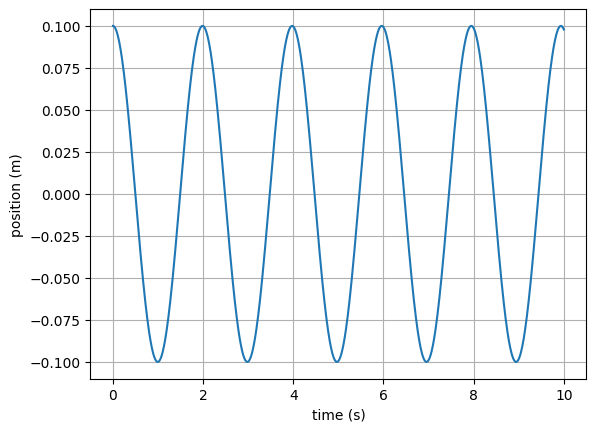

In [34]:
#a
m = 1 
k = 10   
x0 = 0.1
v0 = 0 
t = np.linspace(0, 10, 1000)
x = x0 * np.cos(np.sqrt(k/m)*t) + v0 * np.sqrt(m/k) * np.sin(np.sqrt(k/m)*t)
plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("position (m)")
plt.grid()
plt.show()

In [25]:
#b
from scipy.integrate import solve_ivp
def f(t, y):
    x, v = y
    return [v, -(k/m)*x]
y0 = [x0, v0]
sol = solve_ivp(f, [0, 10], y0, t_eval=t)
x_numerical = sol.y[0]

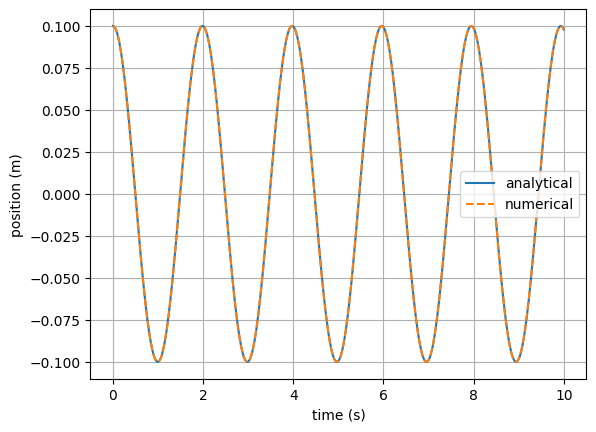

maximum error: 0.0008795534971236308


In [35]:
#c
plt.plot(t, x, label="analytical")
plt.plot(t, x_numerical, "--", label="numerical")
plt.xlabel("time (s)")
plt.ylabel("position (m)")
plt.legend()
plt.grid()
plt.show()
error = np.max(np.abs(x - x_numerical))
print("maximum error:", error)